In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from torch import optim
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import copy
import torch.nn.functional as F
from tqdm import tqdm
from sklearn.utils.class_weight import compute_class_weight

# Dataset
Load dataset

In [2]:
train_images = np.load('dermamnist_128/train_images.npy')
train_labels = np.load('dermamnist_128/train_labels.npy')

val_images = np.load('dermamnist_128/val_images.npy')
val_labels = np.load('dermamnist_128/val_labels.npy')

test_images = np.load('dermamnist_128/test_images.npy')
test_labels = np.load('dermamnist_128/test_labels.npy')

FileNotFoundError: [Errno 2] No such file or directory: 'dermamnist_128/train_images.npy'

Check shape of your data

In [ ]:
print('Train images size:', train_images.shape)
print('Train labels size:', train_labels.shape)
print('')
print('Validation images size:',val_images.shape)
print('Validation images size:',val_labels.shape)
print('')
print('Test images size:',test_images.shape)
print('Test images size:',test_labels.shape)

Train images size: (7007, 128, 128, 3)
Train labels size: (7007, 1)

Validation images size: (1003, 128, 128, 3)
Validation images size: (1003, 1)

Test images size: (2005, 128, 128, 3)
Test images size: (2005, 1)


**Classes**  
0 : akiec, Actinic keratoses and intraepithelial carcinoma / Bowen's disease  
1 : bcc, basal cell carcinoma (bcc)  
2 : bkl, benign keratosis-like lesions (solar lentigines / seborrheic keratoses and lichen-planus like keratoses)   
3 : df, dermatofibroma (df)  
4 : nv, melanocytic nevi  
5 : vasc, vascular lesions (angiomas, angiokeratomas, pyogenic granulomas and hemorrhage)  
6 : mel, melanoma  

In [ ]:
classDict = {0 : 'akiec',
1 : 'bcc',
2 : 'bkl',
3 : 'df',
4 : 'nv',
5 : 'vasc',
6 : 'mel'}

### Visualize Random Samples

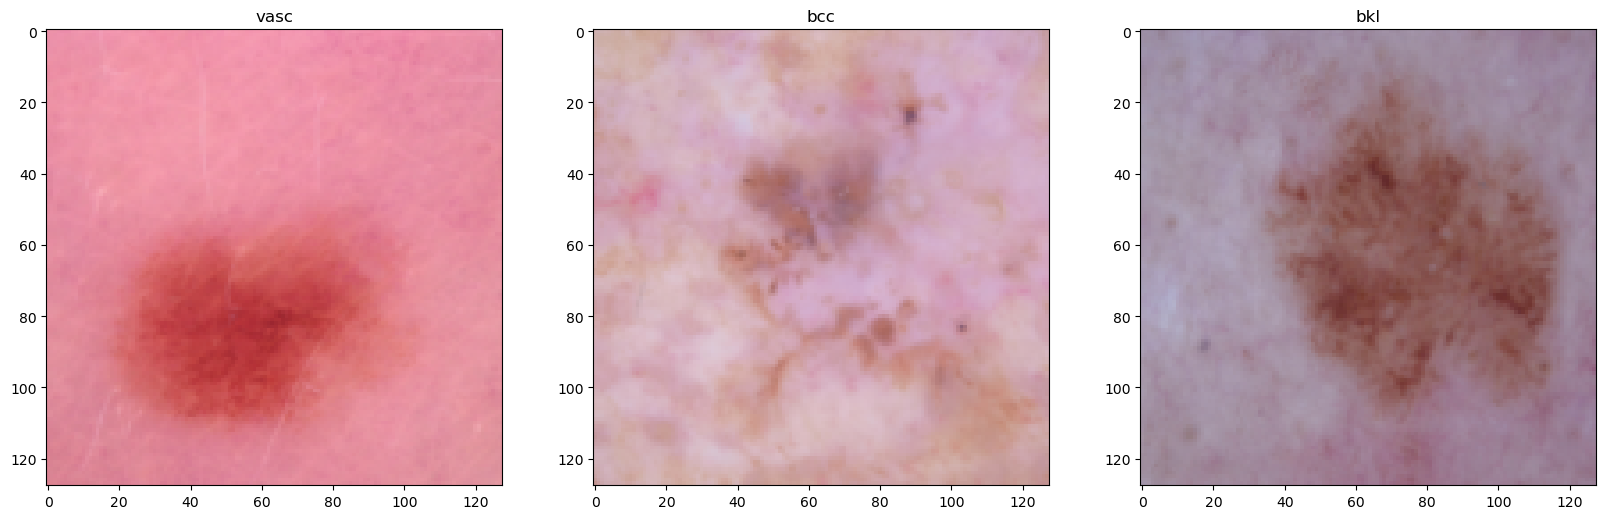

In [ ]:
fig, axs = plt.subplots(1, 3)
fig.set_figheight(8)
fig.set_figwidth(20)
selected_indices = np.random.randint(0, high=len(train_images), size=3)
for i in range(0,3):
    axs[i].imshow(train_images[selected_indices[i]])
    axs[i].title.set_text(classDict[train_labels[selected_indices[i]].item()])

### Plot class distribution of your data.

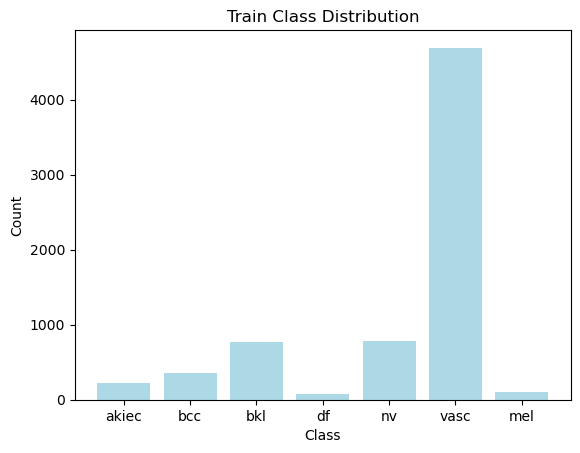

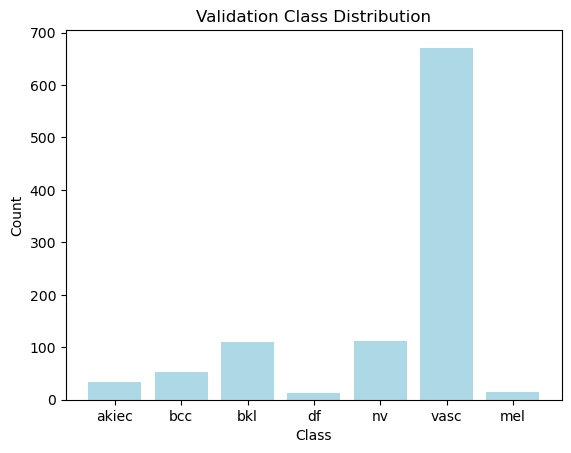

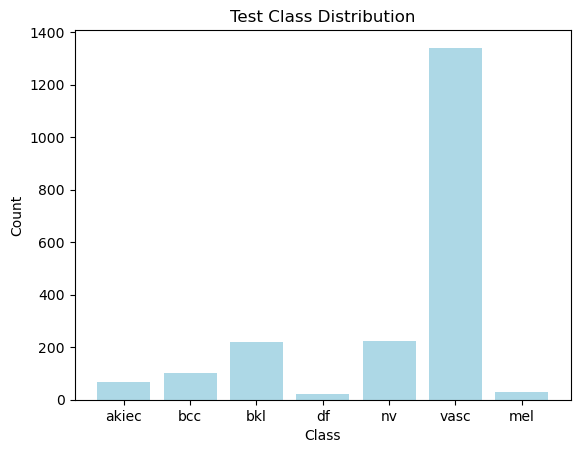

In [ ]:
class_names = [class_name for class_name in classDict.values()]


# Train Class Distribution
train_class_counts = np.zeros(len(classDict), dtype=int)

for i in range(len(train_labels)):
    train_class_counts[train_labels[i]] += 1

plt.bar(class_names, train_class_counts, color='lightblue')
plt.title("Train Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

# Validation Class Distribution
validation_class_counts = np.zeros(len(classDict), dtype=int)

for i in range(len(val_labels)):
    validation_class_counts[val_labels[i]] += 1

plt.bar(class_names, validation_class_counts, color='lightblue')
plt.title("Validation Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

# Test Class Distribution
test_class_counts = np.zeros(len(classDict), dtype=int)

for i in range(len(test_labels)):
    test_class_counts[test_labels[i]] += 1

plt.bar(class_names, test_class_counts, color='lightblue')
plt.title("Test Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [ ]:
# Class imbalance handling
train_labels_flat = train_labels.flatten()

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels_flat),
    y=train_labels_flat
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to("cuda:0")

AssertionError: Torch not compiled with CUDA enabled

### Create Dataset Class

In [ ]:
class DermoDataset(Dataset):
    def __init__(self, images, labels, classDict, input_size=(128,128), augmentation=False):
        super(Data_Classifier, self).__init__()
        self.image_list = images
        self.label_list = labels
        self.augmentation = augmentation
        self.classDict = classDict
        self.height = input_size[0]
        self.width = input_size[1]

    def transform(self, img, label):
        #### TODO ####
        #### Normalization, Augmentation, Tensor Conversion, Image Resizing #####







        return img, label

    def __getitem__(self, index):
        #### TODO ####

        # read image and label with index #
        image = self.image_list[index]
        label = self.label_list[index]
        # transform
        current_image = transform(image)
        current_label = transform(label)

        return current_image, current_label

    def __len__(self):
        #### TODO ####
        return len(self.image_list)t

In [ ]:
train_dataset = DermoDataset(train_images, train_labels, classDict)
val_dataset = DermoDataset(val_images, val_labels, classDict)
print('Train set size:', len(train_dataset))
print('Val set size:', len(val_dataset))

### Create DataLoader
You should tune batch size

In [ ]:
batch_size = 4
#### TODO ####

In [ ]:
dataloaders = {
    'train': train_loader,
    'val': val_loader
}

# Create Model

In [ ]:
class SimpleCNN(torch.nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        #### TODO ####
    def forward(self, x):
        #### TODO ####
        return x

In [ ]:
class ResNet50Classifier(nn.Module):
    def __init__(
            self,
            ch,
            num_class,
            freeze
    ):
        super(ResNet50Classifier, self).__init__()
        #### TODO ####

    def forward(self, x):
        #### TODO ####

        return x

In [ ]:
class Vit16Classifier(nn.Module):
    def __init__(
            self,
            ch,
            num_class,
            freeze
    ):
        super(Vit16Classifier, self).__init__()
        #### TODO ####

    def forward(self, x):
        #### TODO ####

        return x

In [ ]:
model = SimpleCNN()
model.to(device="cuda:0")

In [ ]:
model = ResNet50Classifier(3, 7, False)
model.to(device="cuda:0")

In [ ]:
model = Vit16Classifier(3, 7, False)
model.to(device="cuda:0")

# Training

### Set Optimizer with parameters

In [ ]:
lrRate =
weightDecay =
numberOfEpoch =
early_stop =
device = "cuda:0"
dtype = torch.cuda.FloatTensor
optimizer = #### TODO ####

### Loss Function

In [ ]:
calc_loss =  #### TODO ####

### Train Loop

In [ ]:
def train(model, dataloaders, calc_loss, optimizer, numberOfEpoch, early_stop, device, dtype):
    best_model = copy.deepcopy(model.state_dict())
    best_loss = 1e7
    early_stop_counter = 0
    train_loss_list = []
    val_loss_list = []

    total_memory = f'{torch.cuda.get_device_properties(0).total_memory/ 1E9 if torch.cuda.is_available() else 0:.3g}G'
    for epoch in range(0, numberOfEpoch):
        # Each epoch has a training and validation phase
        for phase in ['train','val']:
            epoch_loss = 0.0
            correct_prediction = 0.0
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()  # Set model to evaluate mode
            batch_step = 0
            batch_size = dataloaders[phase].batch_size
            with tqdm(dataloaders[phase], unit="batch") as tbar:
                for input_imgs, gt_labels in tbar:
                    tbar.set_description(f"Epoch {epoch}")
                    batch_step += 1
                    input_imgs = input_imgs.to(device).type(dtype)
                    gt_labels = gt_labels.to(device).type(dtype)

                    #### TODO ####

    return best_model, train_loss_list, val_loss_list

In [ ]:
best_model, train_loss_list, val_loss_list = train(model, dataloaders, calc_loss, optimizer, 5, early_stop, device, dtype)

### Visualization
plot training and validation loss

In [ ]:
#### TODO ####

# Test

In [ ]:
model = ResNet50Classifier(3, 7, False) ### Change with which model you are currently using
#### Load best model #####
#### TODO ####
for i in range(0,len(test_images)):
    current_test_img = test_images[i,:,:]
    #### TODO ####

### Evaluation Metrics ###
Overall accuracy, confusion matrix, and precision, recall, f1 score for each class.

In [ ]:
#### TODO ####